In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [29]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [30]:
len(words)

32033

In [31]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [32]:
# build the dataset
block_size = 3 # how many characters do we take to pridict the next one
X,Y = [],[]
for w in words[:5]:
    print(w)
    context = [0] * block_size
    for ch in w+'.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        print(''.join(itos[i] for i in context), '---->', itos[ix])
        context = context[1:] + [ix] # crop and append
X = torch.tensor(X)
Y = torch.tensor(Y)

In [33]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [7]:
C = torch.randn((27,2))

In [8]:
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [9]:
W1 = torch.randn([6, 100])
b1 = torch.randn(100)

In [10]:
h = torch.tanh(emb.view(emb.shape[0],6)@W1+b1)
h.shape

torch.Size([32, 100])

In [11]:
W2 = torch.randn([100,27])
b2 = torch.randn(27)

In [12]:
logits = h @ W2 + b2

In [13]:
logits.shape

torch.Size([32, 27])

In [14]:
counts = logits.exp()

In [15]:
prob = counts / counts.sum(1, keepdims=True)

In [16]:
prob.shape

torch.Size([32, 27])

In [17]:
prob[0].sum()

tensor(1.0000)

In [18]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

tensor(12.6512)

In [68]:
def build_datasets(words):
    block_size = 3 # how many characters do we take to pridict the next one
    X,Y = [],[]
    for w in words:
        context = [0] * block_size
        for ch in w+'.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[i] for i in context), '---->', itos[ix])
            context = context[1:] + [ix] # crop and append
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X,Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
Xtr, Ytr = build_datasets(words[:n1])
Xdev, Ydev = build_datasets(words[n1:n2])
Xte, Yte = build_datasets(words[n2:])

torch.Size([182441, 3]) torch.Size([182441])
torch.Size([22902, 3]) torch.Size([22902])
torch.Size([22803, 3]) torch.Size([22803])


In [69]:
# ----------------- now make respectable --------------------
Xtr.shape, Ytr.shape

(torch.Size([182441, 3]), torch.Size([182441]))

In [94]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,10), generator = g)
W1 = torch.randn((30,200), generator = g)
b1 = torch.randn(200, generator = g)
W2 = torch.randn((200,27), generator = g)
b2 = torch.randn(27, generator = g)
parameters = [C, W1, b1, W2, b2]

In [95]:
sum(p.nelement() for p in parameters)

11897

In [96]:
for p in parameters:
    p.requires_grad=True

In [97]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [106]:
lri = []
lossi = []
stepi = []

In [107]:


for i in range(200000):

    # mini batch construct
    ix = torch.randint(0, Xtr.shape[0], (32,))
    
    # forward pass
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1,30)@W1+b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])
    #print(loss.item())
    # backward pass
    for p in parameters:
        p.grad=None
    loss.backward()
    # update
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr*p.grad

        # track stat
        stepi.append(i)
        lossi.append(loss.log10().item())



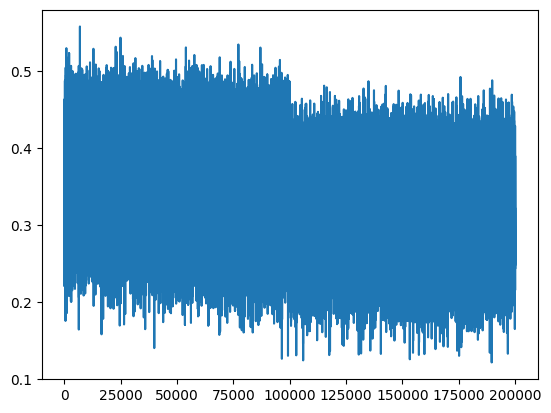

In [108]:
plt.plot(stepi, lossi)

In [104]:
print(loss.item())

2.425666093826294


In [105]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1,30)@W1+b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.2031, grad_fn=<NllLossBackward0>)

In [ ]:
# training split, dev/validation split, test split
# 80%, 10%, 10%

torch.Size([182437, 3]) torch.Size([182437])
torch.Size([22781, 3]) torch.Size([22781])
torch.Size([22928, 3]) torch.Size([22928])
